In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
url = "https://raw.githubusercontent.com/prasertcbs/basic-dataset/master/netflix_titles.csv"
df = pd.read_csv(url)

In [5]:
print("Dataset Loaded Successfully!")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}\n")

Dataset Loaded Successfully!
Total Rows: 6234, Total Columns: 12



In [6]:
df['country'] = df['country'].fillna('Unknown')
df['director'] = df['director'].fillna('Not Specified')
df['cast'] = df['cast'].fillna('Not Specified')

In [7]:
df.dropna(subset=['date_added', 'rating'], inplace=True)

In [8]:
df['year_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce').dt.year

print("Missing values after cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0])

Missing values after cleaning:
 Series([], dtype: int64)


Text(0.5, 0.98, 'Netflix Movies & TV Shows - Exploratory Data Analysis')

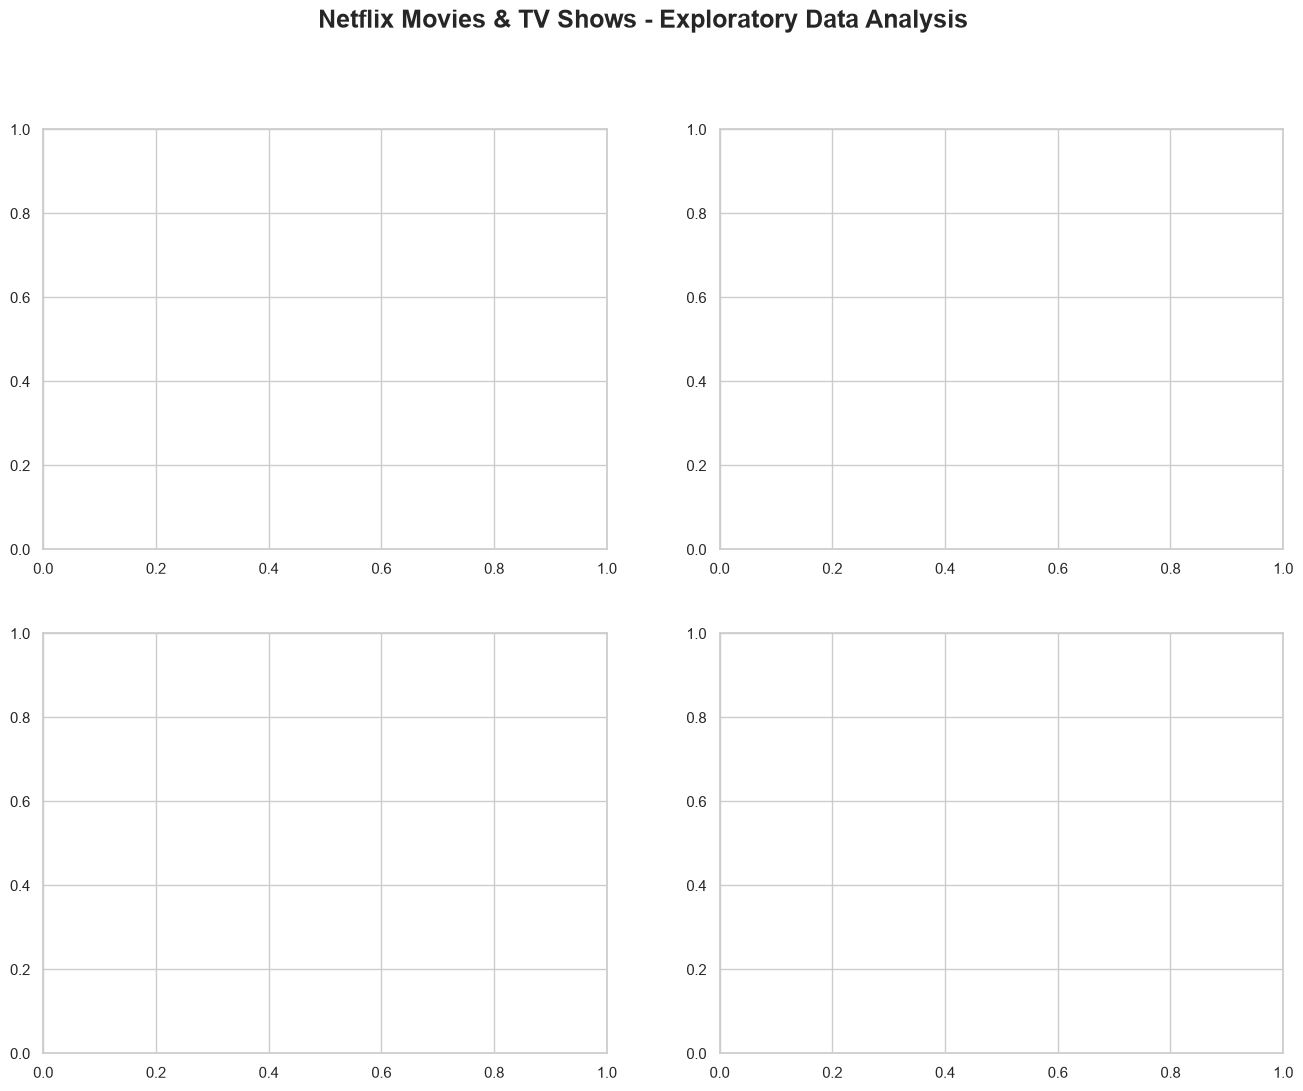

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Netflix Movies & TV Shows - Exploratory Data Analysis', fontsize=18, fontweight='bold')

In [10]:
sns.countplot(data=df, x='type', ax=axes[0, 0], hue='type', palette='Set2', legend=False)
axes[0, 0].set_title('1. Distribution of Movies vs TV Shows', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Content Type')
axes[0, 0].set_ylabel('Total Count')

Text(4.444444444444459, 0.5, 'Total Count')

In [11]:
top_countries = df[df['country'] != 'Unknown']['country'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[0, 1], hue=top_countries.index, palette='viridis', legend=False)
axes[0, 1].set_title('2. Top 10 Content Producing Countries', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Number of Titles')
axes[0, 1].set_ylabel('Country')

Text(680.8080808080806, 0.5, 'Country')

In [12]:
yearly_trend = df[df['release_year'] >= 2005]['release_year'].value_counts().sort_index()
axes[1, 0].plot(yearly_trend.index, yearly_trend.values, marker='o', color='#E50914', linewidth=2.5)
axes[1, 0].set_title('3. Content Release Trend (2005 - Present)', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Release Year')
axes[1, 0].set_ylabel('Number of Releases')

Text(4.444444444444459, 0.5, 'Number of Releases')

In [13]:
top_ratings = df['rating'].value_counts().head(8)
sns.barplot(x=top_ratings.index, y=top_ratings.values, ax=axes[1, 1], hue=top_ratings.index, palette='magma', legend=False)
axes[1, 1].set_title('4. Top Content Ratings Distribution', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Rating Category')
axes[1, 1].set_ylabel('Count')

Text(680.8080808080806, 0.5, 'Count')

In [14]:
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('netflix_eda_dashboard.png', dpi=300) # Saves high-res image for LinkedIn/README
plt.show()

<Figure size 640x480 with 0 Axes>

In [15]:
movie_pct = round((df['type'].value_counts(normalize=True)['Movie']) * 100, 1)
tv_pct = round((df['type'].value_counts(normalize=True)['TV Show']) * 100, 1)

In [16]:
print("\n" + "="*40)
print("       KEY PROJECT INSIGHTS")
print("="*40)
print(f"• Total Titles Analyzed : {len(df)}")
print(f"• Content Split         : {movie_pct}% Movies vs {tv_pct}% TV Shows")
print(f"• Top Producing Country : {top_countries.idxmax()} ({top_countries.max()} titles)")
print(f"• Most Common Rating    : {top_ratings.idxmax()} ({top_ratings.max()} titles)")
print(f"• Peak Release Year     : {yearly_trend.idxmax()} ({yearly_trend.max()} releases)")
print("="*40)


       KEY PROJECT INSIGHTS
• Total Titles Analyzed : 6214
• Content Split         : 68.5% Movies vs 31.5% TV Shows
• Top Producing Country : United States (2023 titles)
• Most Common Rating    : TV-MA (2025 titles)
• Peak Release Year     : 2018 (1062 releases)
